# Da planilha ao script: análise reprodutível com R
**Aula-amostra · Workshop "Pesquisa reprodutível na prática"**

### O problema
Uma análise feita clicando numa planilha ou num programa como o Prism produz um resultado, mas **não registra o caminho**: como a tabela foi rearranjada, que linhas foram excluídas, que teste foi usado, com que opções. Dois anos depois, nem o próprio autor consegue refazer.

**Pergunta para a turma:** quem aqui conseguiria refazer exatamente uma análise de dois anos atrás?

### A proposta
Um notebook junta, num só documento, **o texto que explica, o código que executa e o resultado que aparece**. Ele é, ao mesmo tempo, a análise e o relatório. E isso vale desde o primeiro passo: **arrumar os dados também é parte da análise**.

**Dados (simulados, criados para o workshop):** pressão arterial sistólica (mmHg) de 60 ratos hipertensos, tratados com um de dois fármacos (`A` ou `B`) em uma de três doses (1, 3 ou 10 mg/kg), com 10 animais por grupo. Aqui eles chegam com um grupo por coluna, como os dados costumam ser digitados em planilhas e em programas como o Prism.

## 0. Plano de análise (definido antes de olhar os dados)
- **Desenho:** dois fármacos (A e B), três doses (1, 3 e 10 mg/kg), 10 animais por grupo.
- **Pergunta principal (confirmatória):** na dose de 1 mg/kg, a pressão arterial sistólica média difere entre os fármacos A e B? Teste t de Welch, bilateral, com nível de significância de 5%, relatando a diferença entre as médias com intervalo de confiança de 95%.
- **Descrição:** médias, desvios-padrão e gráfico de todos os grupos.
- **Qualquer análise fora deste plano** será relatada como **exploratória**.

> Numa pesquisa real, este plano seria registrado publicamente antes da coleta dos dados, num repositório como o OSF, com data e sem possibilidade de alteração. Aqui ele serve de modelo.

## 1. Ler os dados como eles chegam
Os dados estão depositados no **Zenodo**, um repositório de dados de pesquisa, com DOI e licença próprios ([10.5281/zenodo.24328555](https://doi.org/10.5281/zenodo.24328555)). Este notebook fica no GitHub, com licença própria: **dados e código são publicados separadamente**, cada um no lugar adequado.

Lemos o arquivo direto pela URL: o caminho até o dado fica registrado no próprio código, e qualquer pessoa que abrir este notebook reproduz a análise. **O arquivo original nunca é alterado.**

Carregamos apenas os pacotes que a análise usa: quem ler o código sabe exatamente do que ela depende.

In [1]:
# Comentário: tudo o que vem depois de # numa linha é ignorado pelo R e serve só para quem lê o código
library(readr)    # ler arquivos
library(dplyr)    # manipular dados
library(tidyr)    # arrumar dados (formato tidy)
library(ggplot2)  # gráficos


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [15]:
# Consulta à documentação da função - ?nome_da_funcao
?read_csv

In [11]:
# read_csv aceita uma url - ótimo pra reprodutibilidade
# Arquivo da versão publicada no Zenodo (DOI 10.5281/zenodo.24328555)
url_dados <- "https://zenodo.org/records/24328555/files/pressao_largo.csv?download=1" # Criando um objeto (um valor com um nome)

In [17]:
# Importando os dados para dentro do R
largo <- read_csv(url_dados)

Rows: 10 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (6): A_1, A_3, A_10, B_1, B_3, B_10

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [18]:
largo

A_1,A_3,A_10,B_1,B_3,B_10
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
170,174,149,199,167,148
178,164,148,186,166,138
168,154,142,190,174,147
190,140,123,187,173,134
179,170,147,175,162,157
169,160,140,183,162,162
180,160,140,183,171,141
183,168,128,186,175,135
181,167,137,197,167,149


> **Pergunta para a turma:** relembrando a oficina de organização de projetos, estes dados estão **arrumados** (*tidy*)?

<details>
<summary><b>Resposta</b> (clique para abrir)</summary>

**Não.** Num conjunto de dados arrumado, cada variável é uma coluna e cada observação é uma linha. Aqui, duas variáveis, o fármaco (`A`, `B`) e a dose (`1`, `3`, `10`), estão escondidas nos **nomes das colunas**, e cada linha não corresponde a um animal: são seis animais diferentes, um em cada coluna.

</details>

## 2. Preparar os dados para a análise
Arrumar a tabela à mão, copiando e colando, funciona, mas não deixa registro e abre espaço para erros. Com código, são três passos, encadeados pelo **pipe** (`|>` ou `%>%`), que entrega o resultado de um passo como entrada do passo seguinte (leia como "e então"):
1. `pivot_longer()`: empilha as seis colunas numa só (`pas`: pressão arterial sistólica), guardando o nome de cada coluna de origem;
2. `separate_wider_delim()`: separa esse nome em fármaco e dose;
3. `mutate()`: transforma a dose em número.

In [24]:
pressao <- largo |>
  pivot_longer(everything(), names_to = "grupo", values_to = "pas") |>
  separate_wider_delim(grupo, delim = "_", names = c("farmaco", "dose")) |>
  mutate(dose = as.numeric(dose))

In [25]:
pressao

farmaco,dose,pas
<chr>,<dbl>,<dbl>
A,1,170
A,3,174
A,10,149
B,1,199
B,3,167
B,10,148
A,1,178
A,3,164
A,10,148


Agora há uma linha por animal (60) e uma coluna por variável (`farmaco`, `dose`, `pas`). A tabela original não foi alterada, e cada passo da transformação está registrado no código.

## 3. Resumir por grupo com o `dplyr`
Com os dados arrumados, cada pergunta vira uma sequência de verbos: agrupar por fármaco e dose (`group_by()`), e então resumir cada grupo (`summarise()`) com o número de animais, a média e o desvio-padrão.

In [33]:
pressao |>
  group_by(farmaco, dose) |>          # um grupo para cada combinação de fármaco e dose
  summarise(                          # calcula, para cada grupo:
    n = n(),                          #   o número de animais
    media = mean(pas),                #   a média da pressão
    desvio_pd = sd(pas),              #   o desvio-padrão da pressão
    .groups = "drop"                  # devolve uma tabela comum, sem os grupos
  )

farmaco,dose,n,media,desvio_pd
<chr>,<dbl>,<int>,<dbl>,<dbl>
A,1,10,177.1,7.030884
A,3,10,162.2,9.647107
A,10,10,139.9,8.595218
B,1,10,188.0,7.226494
B,3,10,169.3,5.207900
B,10,10,145.4,9.131143


## 4. Olhar os dados antes de testar
No `ggplot2`, um gráfico é montado em partes, somadas com `+`:
1. **dados e mapeamentos estéticos** (`aes()`): qual variável vai para o eixo x, qual vai para o y e qual define a cor;
2. **camadas**, cada uma com uma forma geométrica (*geom*): aqui, caixas (`geom_boxplot()`) e um ponto para cada animal (`geom_point()`);
3. **ajustes** de rótulos (`labs()`) e aparência (`theme_minimal()`).

Mostrar os pontos individuais, e não só as caixas, deixa visível cada animal: com 10 por grupo, dá para ver toda a variação.

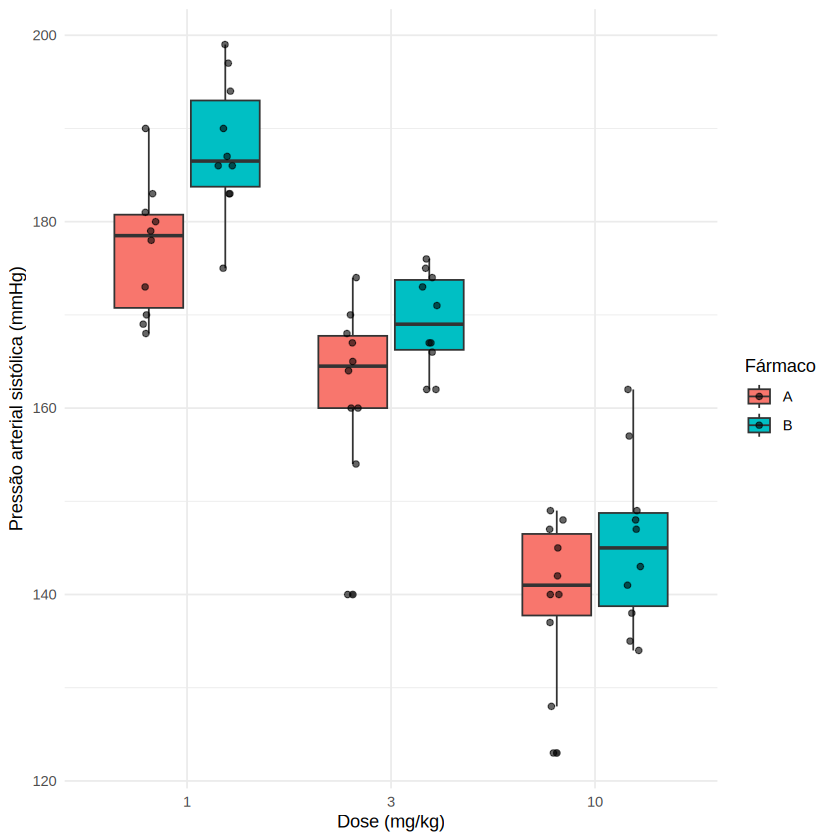

In [34]:
ggplot(pressao, aes(x = factor(dose), y = pas, fill = farmaco)) +   # dados e mapeamentos
  geom_boxplot() +                                                  # camada 1: caixas
  geom_point(position = position_jitterdodge(jitter.width = 0.15),  # camada 2: um ponto por animal
             alpha = 0.6) +
  labs(x = "Dose (mg/kg)", y = "Pressão arterial sistólica (mmHg)",
       fill = "Fármaco") +                                          # rótulos
  theme_minimal()                                                   # aparência

## 5. Testar uma pergunta definida antes
**Na dose de 10 mg/kg, a pressão arterial média difere entre os fármacos?** Teste t de Welch para dois grupos independentes.

In [36]:
pressao |>
  filter(dose == 10) |>
  t.test(pas ~ farmaco, data = _)


	Welch Two Sample t-test

data:  pas by farmaco
t = -1.3869, df = 17.935, p-value = 0.1825
alternative hypothesis: true difference in means between group A and group B is not equal to 0
95 percent confidence interval:
 -13.833483   2.833483
sample estimates:
mean in group A mean in group B 
          139.9           145.4 


Como definido no plano, o que importa relatar é a **diferença entre as médias e o seu intervalo de confiança**, não só o valor de p.

> **Pergunta para a turma:** o teste mostrou que, na dose de 1 mg/kg, a pressão difere entre os fármacos A e B. Com estes dados, podemos dizer que algum dos dois **reduz** a pressão?

<details>
<summary><b>Resposta</b> (clique para abrir)</summary>

**Não.** Falta um **grupo controle** (veículo ou placebo). Sem ele, só podemos comparar os fármacos entre si: não sabemos como a pressão estaria sem tratamento. A pergunta define o desenho, e o desenho define o que se pode concluir.

</details>

> **Pergunta para a turma:** e se agora testarmos a mesma comparação na dose de 10 mg/kg? O resultado teria o mesmo peso que o anterior?

<details>
<summary><b>Resposta</b> (clique para abrir)</summary>

**Não.** Essa comparação não estava no plano: é uma **análise exploratória**. Ela pode sugerir hipóteses para um próximo estudo, mas não as confirma. Cada teste a mais aumenta a chance de um resultado "significativo" por acaso.

Se a pergunta também interessa nas outras doses, o caminho é **incluir essas comparações no plano desde o início** e **corrigir para comparações múltiplas** (por exemplo, pelo método de Holm). O que não se pode é testar várias comparações e relatar só a que deu certo, como se fosse a principal: isso é *p-hacking*.

</details>

## 6. O teste de reprodutibilidade
Antes de compartilhar: **Reiniciar e executar tudo**. Se o notebook roda do início ao fim numa sessão limpa e dá os mesmos resultados, ele é reprodutível. Por fim, registramos as versões usadas.

In [ ]:
sessionInfo()

## E depois?
**No bloco seguinte:** é o caminho que estes dados já fizeram. Os dados vão para o Zenodo, com DOI e licença CC BY; o notebook vai para o GitHub, com a sua licença.

> **E os dados de vocês?** Para uma planilha que ainda não está num repositório, dá para começar subindo o arquivo pelo painel de arquivos do Colab (ícone de pasta, à esquerda) e lendo com `read_csv("nome_do_arquivo.csv")`. Mas o arquivo some quando o ambiente é reiniciado, e quem abrir o notebook depois não vai encontrá-lo. O ideal é que o dado tenha um endereço fixo, num repositório: é o que veremos no próximo bloco.